<a href="https://colab.research.google.com/github/Nasim-Amani/grid-failure/blob/main/daily_feeder_health.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
# ==========================================
# Step: Create Daily Feeder Health Dataset
# ==========================================

import pandas as pd
import numpy as np


# ------------------------------------------
# 1. Read reference dataset
# ------------------------------------------

path = "/content/feeders_clean_outage_reference.csv"

df = pd.read_csv(path)

df["datetime"] = pd.to_datetime(df["datetime"])

# Create daily date
df["date"] = df["datetime"].dt.date


print("Reference shape:")
print(df.shape)

Reference shape:
(2764, 49)


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2764 entries, 0 to 2763
Data columns (total 49 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   ردیف                         2764 non-null   int64         
 1   روز هفته                     2764 non-null   object        
 2   ردیف یکتا                    2764 non-null   int64         
 3   منطقه اصلی                   2764 non-null   object        
 4   تاریخ اطلاع                  2764 non-null   object        
 5   ساعت اطلاع                   2764 non-null   object        
 6   پست فوق توزیع                2754 non-null   object        
 7   کد پست فوق توزیع             2754 non-null   float64       
 8   فیدر فشار متوسط              2764 non-null   object        
 9   کد فیدر فشار متوسط           2764 non-null   int64         
 10  پست توزیع                    2658 non-null   object        
 11  کد پست توزیع                 0 non-null    

In [16]:
# ==========================================
# Rename columns to English names
# ==========================================

rename_map = {

    "ردیف": "row_id",
    "روز هفته": "weekday_name",
    "ردیف یکتا": "event_id",

    "منطقه اصلی": "region",

    "تاریخ اطلاع": "report_date",
    "ساعت اطلاع": "report_time",

    "پست فوق توزیع": "upstream_substation",
    "کد پست فوق توزیع": "upstream_substation_code",

    "فیدر فشار متوسط": "mv_feeder",
    "کد فیدر فشار متوسط": "mv_feeder_code",

    "پست توزیع": "distribution_substation",
    "کد پست توزیع": "distribution_substation_code",

    "فیدر فشار ضعیف": "lv_feeder",

    "آدرس": "address",

    "سطح ولتاژ": "voltage_level",

    "گروه قطع": "outage_group",
    "علت قطع": "outage_reason",

    "اشکال": "fault_type",
    "علت اشکال": "fault_reason",

    "جریان قطع اولیه": "initial_current",

    "بار قطع شده (MWH)": "interrupted_load_mwh",
    "انرژی توزیع نشده (KWH)": "energy_not_supplied_kwh",

    "مدت قطع": "outage_duration",

    "جداکننده": "switch_device",

    "نوع قطعی": "outage_type",

    "وضعیت محل": "location_status",

    "تکی یا کلی به تشخیص اپراتور": "outage_scope",

    "زون": "zone",

    "شرح حادثه": "incident_description",

    "زمان قطع": "outage_start",
    "زمان وصل": "outage_end",

    "مدت زمان خاموشی به دقیقه": "outage_minutes",

    "كاربري كه ثبت كرده": "registered_by",

    "نوع پست": "substation_type",

    "گزارش دهنده": "reporter",

    "کاربر ثبت کننده": "created_by",

    "GISCODE پست توزیع": "distribution_gis",

    "GISCODE فیدر فشار متوسط": "mv_feeder_gis",

    "failure_target": "failure_target",

    "date_gregorian": "date_gregorian",

    "datetime": "datetime",

    "year": "year",
    "month": "month",
    "day": "day",
    "hour": "hour",
    "weekday": "weekday",
    "season": "season",

    "date": "date"
}


df_reference = df.rename(
    columns=rename_map
)


print(df_reference.columns.tolist())

['row_id', 'weekday_name', 'event_id', 'region', 'report_date', 'report_time', 'upstream_substation', 'upstream_substation_code', 'mv_feeder', 'mv_feeder_code', 'distribution_substation', 'distribution_substation_code', 'lv_feeder', 'address', 'voltage_level', 'outage_group', 'outage_reason', 'fault_type', 'fault_reason', 'initial_current', 'interrupted_load_mwh', 'energy_not_supplied_kwh', 'outage_duration', 'switch_device', 'outage_type', 'location_status', 'outage_scope', 'zone', 'incident_description', 'outage_start', 'outage_end', 'outage_minutes', 'registered_by', 'substation_type', 'reporter', 'created_by', 'distribution_gis', 'mv_feeder_gis', 'source_file', 'failure_target', 'date_gregorian', 'datetime', 'year', 'month', 'day', 'hour', 'weekday', 'season', 'date']


In [17]:
df_reference.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2764 entries, 0 to 2763
Data columns (total 49 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   row_id                        2764 non-null   int64         
 1   weekday_name                  2764 non-null   object        
 2   event_id                      2764 non-null   int64         
 3   region                        2764 non-null   object        
 4   report_date                   2764 non-null   object        
 5   report_time                   2764 non-null   object        
 6   upstream_substation           2754 non-null   object        
 7   upstream_substation_code      2754 non-null   float64       
 8   mv_feeder                     2764 non-null   object        
 9   mv_feeder_code                2764 non-null   int64         
 10  distribution_substation       2658 non-null   object        
 11  distribution_substation_code  

## Daily Feeder Aggregation Strategy

The original outage dataset contains event-level records (one row = one outage event).
To create a feeder-day health dataset, outage events occurring on the same feeder and the same day are aggregated.

Different aggregation methods are selected based on the physical meaning of each feature:

| Feature | Aggregation Method | Meaning in Daily Feeder Health Dataset |
|---|---|---|
| unplanned_failures | SUM | Total number of unexpected failures occurring on the feeder during the day. Represents failure frequency. |
| total_outages | COUNT | Total number of outage records (planned + unplanned). Represents overall outage activity. |
| planned_outages | Conditional SUM | Number of planned maintenance outages. Separates operational activities from real failures. |
| total_duration | SUM | Total interruption time accumulated during the day. Represents overall outage burden. |
| max_duration | MAX | Duration of the most severe single outage event. Captures extreme failure severity. |
| total_energy_loss | SUM | Total energy not supplied during the day. Represents cumulative customer impact. |
| max_energy_loss | MAX | Highest energy loss caused by a single outage event. Identifies catastrophic events. |
| average_current | MEAN | Average interrupted current level. Represents typical electrical stress during outages. |
| max_interrupted_load | MAX | Maximum interrupted load among events. Captures peak network impact. |
| switching_events | COUNT | Number of switching operations/interventions. Represents operational stress and network activity. |

Aggregation principle:

- **SUM** → used for cumulative effects (number of failures, total duration, total energy loss).
- **MAX** → used for extreme events (worst outage, highest impact).
- **MEAN** → used for continuous measurements where the average condition is meaningful.
- **COUNT** → used for frequency of events or operational actions.

Keeping both cumulative and extreme indicators allows the model to distinguish between:
- feeders with frequent small disturbances,
- feeders with rare but highly damaging failures.

In [18]:
# ==========================================
# Daily Numerical Feeder Aggregation
# ==========================================

import pandas as pd


# ------------------------------------------
# Create daily feeder health numerical features
# ------------------------------------------

daily_numeric = (
    df_reference
    .groupby(
        [
            "mv_feeder_gis",
            "date"
        ]
    )
    .agg(

        # --------------------------
        # Failure behavior
        # --------------------------

        unplanned_failures=(
            "failure_target",
            "sum"
        ),

        total_outages=(
            "failure_target",
            "count"
        ),

        planned_outages=(
            "failure_target",
            lambda x: (x == 0).sum()
        ),


        # --------------------------
        # Impact
        # --------------------------

        total_duration=(
            "outage_minutes",
            "sum"
        ),

        max_duration=(
            "outage_minutes",
            "max"
        ),

        total_energy_loss=(
            "energy_not_supplied_kwh",
            "sum"
        ),

        max_energy_loss=(
            "energy_not_supplied_kwh",
            "max"
        ),


        # --------------------------
        # Electrical stress
        # --------------------------

        average_current=(
            "initial_current",
            "mean"
        ),

        max_interrupted_load=(
            "interrupted_load_mwh",
            "max"
        ),


        # --------------------------
        # Operational activity
        # --------------------------

        switching_events=(
            "switch_device",
            "count"
        )

    )
    .reset_index()
)


print("Daily numerical dataset shape:")
print(daily_numeric.shape)


display(
    daily_numeric.head()
)

Daily numerical dataset shape:
(2036, 12)


,mv_feeder_gis,date,unplanned_failures,total_outages,planned_outages,total_duration,max_duration,total_energy_loss,max_energy_loss,average_current,max_interrupted_load,switching_events
0,112240,2016-03-24,1,1,0,36,36,16.750440,16.750440,79.0,0.027917,1
1,112240,2016-03-29,1,1,0,70,70,84.277742,84.277742,2.0,0.058824,1
2,112240,2016-04-05,1,1,0,47,47,5.867878,5.867878,70.0,0.007491,1
3,112240,2016-04-06,0,1,1,20,20,8.471666,8.471666,87.0,0.025415,1
4,112240,2016-04-15,1,1,0,139,139,51.703025,51.703025,79.0,0.022318,1


In [19]:
# ==========================================
# Keep truly static feeder information
# ==========================================

static_cols = [
    "mv_feeder_gis",
    "mv_feeder_code",
    "mv_feeder",
    "upstream_substation",
    "upstream_substation_code"
]


static_info = (
    df_reference[static_cols]
    .drop_duplicates(
        "mv_feeder_gis"
    )
)


daily_health = daily_numeric.merge(
    static_info,
    on="mv_feeder_gis",
    how="left"
)


print("Daily health shape:")
print(daily_health.shape)


display(
    daily_health.head()
)

Daily health shape:
(2036, 16)


,mv_feeder_gis,date,unplanned_failures,total_outages,planned_outages,total_duration,max_duration,total_energy_loss,max_energy_loss,average_current,max_interrupted_load,switching_events,mv_feeder_code,mv_feeder,upstream_substation,upstream_substation_code
0,112240,2016-03-24,1,1,0,36,36,16.750440,16.750440,79.0,0.027917,1,25794022,MV_شریعتی_زمرد,شریعتی,257.0
1,112240,2016-03-29,1,1,0,70,70,84.277742,84.277742,2.0,0.058824,1,25794022,MV_شریعتی_زمرد,شریعتی,257.0
2,112240,2016-04-05,1,1,0,47,47,5.867878,5.867878,70.0,0.007491,1,25794022,MV_شریعتی_زمرد,شریعتی,257.0
3,112240,2016-04-06,0,1,1,20,20,8.471666,8.471666,87.0,0.025415,1,25794022,MV_شریعتی_زمرد,شریعتی,257.0
4,112240,2016-04-15,1,1,0,139,139,51.703025,51.703025,79.0,0.022318,1,25794022,MV_شریعتی_زمرد,شریعتی,257.0



## Static Feeder Information

Static features describe the identity and location of each feeder, not daily outage behavior.

These columns are kept without aggregation because they remain constant for a feeder and provide important context for the model.

Examples:
- mv_feeder_gis → unique feeder identifier
- mv_feeder_code → operational feeder code
- mv_feeder → feeder name
- upstream_substation → connected upstream substation
- upstream_substation_code → upstream asset identifier
- region → geographic area

These features help the model learn whether specific feeders, locations, or network assets have different historical failure risks.

Dynamic network features (such as distribution substations, LV feeders, zones, voltage level, and substation type) will be added separately because they may vary over time.

In [20]:
# ==========================================
# Multi-hot encode dynamic network features
# ==========================================

multi_hot_cols = [
    "region",
    "zone",
    "distribution_substation",
    "distribution_gis",
    "substation_type",
    "voltage_level",
    "lv_feeder"
]


for col in multi_hot_cols:

    temp = (
        df_reference[
            [
                "mv_feeder_gis",
                "date",
                col
            ]
        ]
        .dropna()
        .drop_duplicates()
    )


    # Convert categories into binary columns
    encoded = pd.get_dummies(
        temp[col],
        prefix=col
    )


    temp_encoded = pd.concat(
        [
            temp[
                [
                    "mv_feeder_gis",
                    "date"
                ]
            ].reset_index(drop=True),

            encoded.reset_index(drop=True)

        ],
        axis=1
    )


    # If multiple categories exist in one feeder-day,
    # keep all of them
    temp_encoded = (
        temp_encoded
        .groupby(
            [
                "mv_feeder_gis",
                "date"
            ]
        )
        .max()
        .reset_index()
    )


    daily_health = daily_health.merge(
        temp_encoded,
        on=[
            "mv_feeder_gis",
            "date"
        ],
        how="left"
    )


print("New daily health shape:")
print(daily_health.shape)

New daily health shape:
(2036, 426)


## Dynamic Network Feature Encoding

Some network characteristics can change within the same feeder-day because a feeder may supply multiple downstream assets.

Instead of selecting only one value, categorical network information is converted into multi-hot features.

Example:

A feeder-day containing:

- Substation A
- Substation B

becomes:

distribution_substation_A = 1
distribution_substation_B = 1

This preserves network topology information.

Encoded dynamic features:
- region
- zone
- distribution substation
- distribution GIS asset
- substation type
- voltage level
- LV feeder

The aggregation rule is MAX:
- 1 → category exists during that feeder-day
- 0 → category does not exist

This prevents information loss when multiple network elements are involved.

In [21]:
# ==========================================
# Fill missing encoded features
# ==========================================

daily_health = daily_health.fillna(0)


print("Missing values after filling:")
print(
    daily_health.isnull()
    .sum()
    .sum()
)


print("Dataset shape:")
print(daily_health.shape)

Missing values after filling:
0
Dataset shape:
(2036, 426)


## Missing Value Handling After Encoding

After multi-hot encoding and merging different feature groups, some categorical features contain missing values.

These missing values mean that a specific category was not present during that feeder-day.

Example:
- distribution_substation_A = 1 → present
- distribution_substation_A = 0 → not present

Therefore, missing encoded values are replaced with zero.

This step converts the dataset into a fully numerical format suitable for machine learning and deep learning models.

In [22]:
# ==========================================
# Sort feeder history chronologically
# ==========================================

daily_health = daily_health.sort_values(
    [
        "mv_feeder_gis",
        "date"
    ]
).reset_index(drop=True)


print("Sorted successfully.")

display(
    daily_health.head()
)

Sorted successfully.


,mv_feeder_gis,date,unplanned_failures,total_outages,planned_outages,total_duration,max_duration,total_energy_loss,max_energy_loss,average_current,...,lv_feeder_9.0,lv_feeder_10.0,lv_feeder_11.0,lv_feeder_12.0,lv_feeder_13.0,lv_feeder_14.0,lv_feeder_15.0,lv_feeder_21.0,lv_feeder_9999.0,lv_feeder_101782.0
0,112240,2016-03-24,1,1,0,36,36,16.750440,16.750440,79.0,...,False,False,False,False,False,False,False,False,False,False
1,112240,2016-03-29,1,1,0,70,70,84.277742,84.277742,2.0,...,0,0,0,0,0,0,0,0,0,0
2,112240,2016-04-05,1,1,0,47,47,5.867878,5.867878,70.0,...,False,False,False,False,False,False,False,False,False,False
3,112240,2016-04-06,0,1,1,20,20,8.471666,8.471666,87.0,...,False,False,False,False,False,False,False,False,False,False
4,112240,2016-04-15,1,1,0,139,139,51.703025,51.703025,79.0,...,False,False,False,False,False,False,False,False,False,False


## Temporal Ordering

The dataset is sorted by feeder identity and date.

This ensures that each feeder has a continuous chronological history:

Feeder A:
Day 1
Day 2
Day 3
...

Feeder B:
Day 1
Day 2
Day 3
...

Correct time ordering is required before creating prediction targets and temporal sequences for deep learning models.

In [23]:
daily_health.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2036 entries, 0 to 2035
Columns: 426 entries, mv_feeder_gis to lv_feeder_101782.0
dtypes: bool(6), float64(5), int64(8), object(407)
memory usage: 6.5+ MB


##**Checkups**

**Check static feature consistency**

In [24]:
# ==========================================
# Check feeder static information consistency
# ==========================================

static_check_cols = [
    "mv_feeder_code",
    "mv_feeder",
    "upstream_substation",
    "upstream_substation_code",
    "region"
]


static_variation = (
    df_reference
    .groupby("mv_feeder_gis")[static_check_cols]
    .nunique()
)


print("Number of unique values per feeder:")
display(static_variation)


print("\nFeeders with inconsistent static information:")

display(
    static_variation[
        (static_variation > 1).any(axis=1)
    ]
)

Number of unique values per feeder:


,mv_feeder_code,mv_feeder,upstream_substation,upstream_substation_code,region
mv_feeder_gis,,,,,
112240,1,1,1,1,2
112260,1,1,1,1,2
112280,1,1,1,1,1
112320,1,1,1,1,1



Feeders with inconsistent static information:


,mv_feeder_code,mv_feeder,upstream_substation,upstream_substation_code,region
mv_feeder_gis,,,,,
112240,1,1,1,1,2
112260,1,1,1,1,2


In [25]:
# ==========================================
# Inspect conflicting feeder information
# ==========================================

problem_feeders = (
    static_variation[
        (static_variation > 1).any(axis=1)
    ]
    .index
)


df_reference[
    df_reference["mv_feeder_gis"]
    .isin(problem_feeders)
][
    [
        "mv_feeder_gis",
        "mv_feeder",
        "region",
        "upstream_substation"
    ]
].drop_duplicates()

,mv_feeder_gis,mv_feeder,region,upstream_substation
0,112240,MV_شریعتی_زمرد,پاسداران,شریعتی
15,112260,MV_شریعتی_حسینیه ارشاد,پاسداران,شریعتی
106,112240,MV_شریعتی_زمرد,پاسداران,NaN
123,112240,MV_شریعتی_زمرد,نیاوران,NaN
152,112240,MV_شریعتی_زمرد,نیاوران,شریعتی
1687,112260,MV_شریعتی_حسینیه ارشاد,نیاوران,شریعتی


In [26]:
# ==========================================
# Final Daily Health Dataset Inspection
# ==========================================

print("Dataset shape:")
print(daily_health.shape)


# ------------------------------------------
# 1. Check duplicate feeder-day rows
# ------------------------------------------

duplicates = (
    daily_health
    .duplicated(
        subset=[
            "mv_feeder_gis",
            "date"
        ]
    )
    .sum()
)

print("\nDuplicate feeder-day rows:")
print(duplicates)


# ------------------------------------------
# 2. Check days per feeder
# ------------------------------------------

days_per_feeder = (
    daily_health
    .groupby("mv_feeder_gis")["date"]
    .count()
)

print("\nDays per feeder:")
display(days_per_feeder)


# ------------------------------------------
# 3. Check failure distribution
# ------------------------------------------

print("\nUnplanned failure distribution:")
display(
    daily_health["unplanned_failures"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------
# 4. Check total failure days
# ------------------------------------------

failure_days = (
    daily_health["unplanned_failures"] > 0
).sum()

no_failure_days = (
    daily_health["unplanned_failures"] == 0
).sum()


print("\nDays with failures:")
print(failure_days)

print("\nDays without failures:")
print(no_failure_days)


# ------------------------------------------
# 5. Check date range
# ------------------------------------------

print("\nDate range:")
print(
    daily_health["date"].min(),
    "to",
    daily_health["date"].max()
)

Dataset shape:
(2036, 426)

Duplicate feeder-day rows:
0

Days per feeder:


,date
mv_feeder_gis,
112240,663
112260,457
112280,476
112320,440



Unplanned failure distribution:


,count
unplanned_failures,
0,550
1,1166
2,225
3,72
4,18
5,4
6,1



Days with failures:
1486

Days without failures:
550

Date range:
2016-03-24 to 2025-09-20


##**EDA (exploratory data analysis)**

We want to understand:
1. How failures behave over time
2. Which feeders are risky
3. How features relate to failures
4. Whether there are seasonal patterns
5. Whether our aggregation makes sense

###**1) Failure frequency over time (most important)**

Question:

Are failures increasing/decreasing over years?

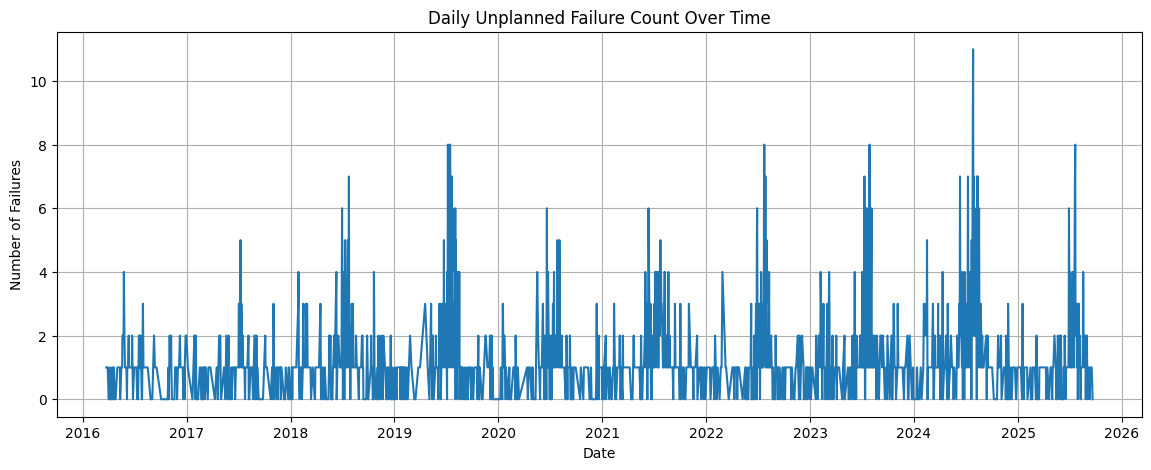

In [27]:
import matplotlib.pyplot as plt

daily_health.groupby("date")["unplanned_failures"].sum().plot(
    figsize=(14,5)
)

plt.title("Daily Unplanned Failure Count Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Failures")
plt.grid(True)
plt.show()

Failure Trend Over Time

The daily failure pattern shows no clear increasing or decreasing trend over the study period (2016–2025).

Failures occur continuously but with significant fluctuations, including several short-term peaks. This indicates that failures are influenced by changing operational and feeder conditions rather than a simple long-term degradation trend.

Therefore, predictive modeling should focus on historical feeder behavior, recent health indicators, and network characteristics rather than relying only on time progression.

###**2) Failure distribution (classification difficulty)**

Question:

How often do we have 0,1,2,... failures per day?

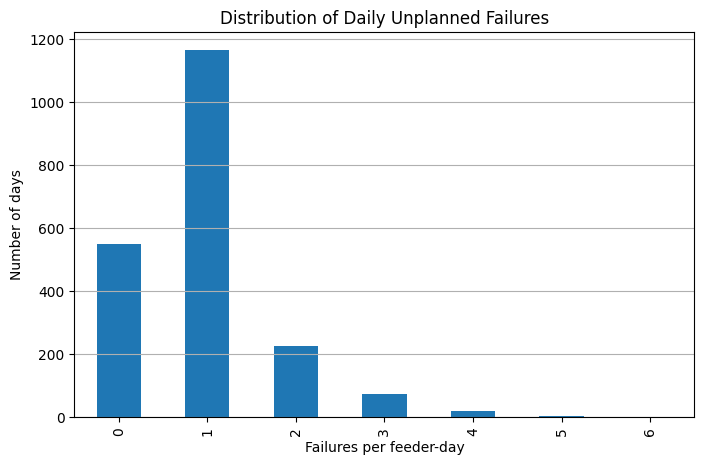

In [28]:
plt.figure(figsize=(8,5))

daily_health["unplanned_failures"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution of Daily Unplanned Failures")
plt.xlabel("Failures per feeder-day")
plt.ylabel("Number of days")
plt.grid(axis="y")
plt.show()

**Failure Distribution**

The daily failure distribution is highly concentrated around low failure counts.

Most feeder-days contain exactly one unplanned failure, while a considerable number of days have no failures. Days with multiple failures are much less frequent, and high failure counts are rare.

This indicates that the prediction problem is dominated by normal/low-event conditions with occasional high-risk periods. Therefore, the model should focus on identifying the transition from normal operation to increased failure risk rather than only predicting large failure events.

###**3) Failure rate by feeder**

Question:

Which feeders are historically more problematic?

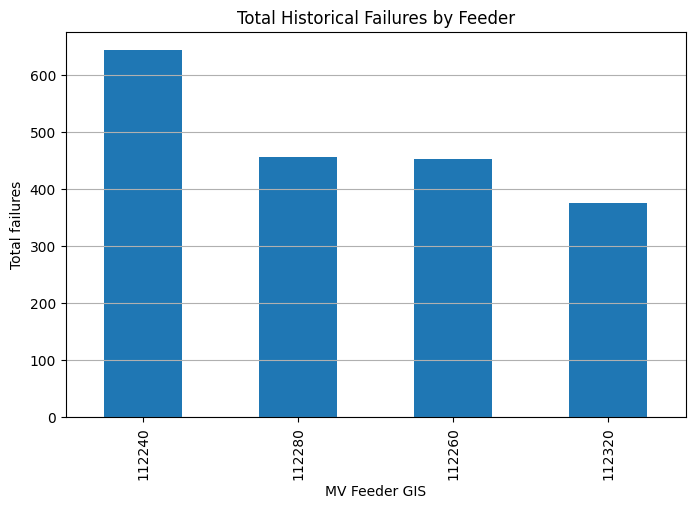

In [29]:
feeder_failure_rate = (
    daily_health
    .groupby("mv_feeder_gis")["unplanned_failures"]
    .sum()
    .sort_values(ascending=False)
)


plt.figure(figsize=(8,5))

feeder_failure_rate.plot(
    kind="bar"
)

plt.title("Total Historical Failures by Feeder")
plt.xlabel("MV Feeder GIS")
plt.ylabel("Total failures")
plt.grid(axis="y")
plt.show()

**Failure Distribution by Feeder**

The historical failure count is not evenly distributed among feeders.

Feeder 112240 has the highest number of recorded unplanned failures, followed by feeders 112280 and 112260, while feeder 112320 shows the lowest total failure count.

This indicates that feeder identity contains useful information about failure behavior. However, total failure count is also influenced by the available observation period, so this comparison should later be normalized using failure rate (failures per feeder-day) before making risk conclusions.

Important note for modeling:

This plot is useful for identifying historically active feeders, but it does not directly mean 112240 is the worst feeder, because your feeders have different history lengths:

- 112240 → 663 days
- 112260 → 457 days
- 112280 → 476 days
- 112320 → 440 days

The next plot (failure probability by feeder) is actually the stronger metric for comparing feeder risk.

###**4) Failure probability by feeder**

Better than total count because feeders have different history lengths.

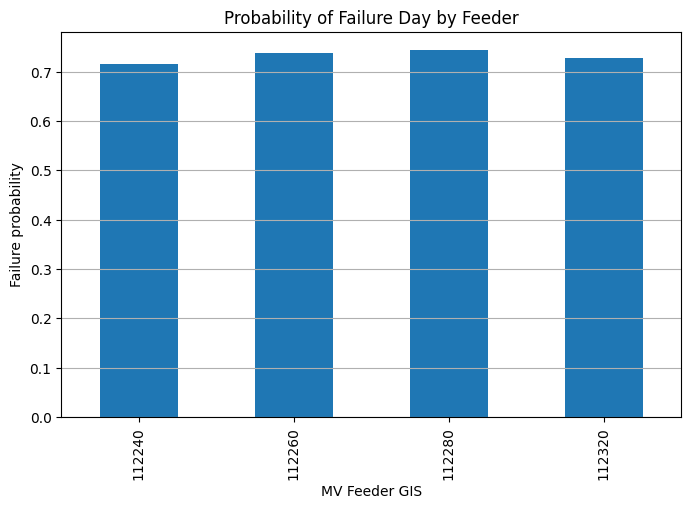

In [30]:
feeder_failure_probability = (
    daily_health
    .groupby("mv_feeder_gis")
    ["unplanned_failures"]
    .apply(lambda x: (x>0).mean())
)


plt.figure(figsize=(8,5))

feeder_failure_probability.plot(
    kind="bar"
)

plt.title("Probability of Failure Day by Feeder")
plt.xlabel("MV Feeder GIS")
plt.ylabel("Failure probability")
plt.grid(axis="y")
plt.show()

**Failure Probability by Feeder**

This analysis normalizes the failure occurrence by feeder observation period and provides a fair comparison between feeders.

The probability of experiencing a failure day is relatively similar across all feeders, with values around 70–75%. Feeder 112280 and 112260 show slightly higher failure-day probabilities, while feeder 112240 and 112320 are slightly lower.

Unlike total failure count, this metric shows that the difference between feeders is not very large. Therefore, feeder identity alone may not be sufficient to explain failure risk, and additional information such as recent failure history, operational conditions, and network characteristics should be considered.


Modeling implication:

Although some feeders have higher historical failure activity, the similar failure probabilities indicate that failures are a network-wide behavior rather than being isolated to a single problematic feeder.

Useful finding for prediction task: **the model should not simply learn "feeder X fails more"; it needs to learn when a feeder becomes high-risk based on changing conditions.**

###**5) Seasonal behavior**

Question:

Are failures higher in some months?

In [34]:
# ==========================================
# Add temporal features for analysis
# ==========================================

daily_health["date"] = pd.to_datetime(
    daily_health["date"]
)


# Calendar features

daily_health["year"] = (
    daily_health["date"].dt.year
)

daily_health["month"] = (
    daily_health["date"].dt.month
)

daily_health["day"] = (
    daily_health["date"].dt.day
)

daily_health["weekday"] = (
    daily_health["date"].dt.weekday
)


print("Time features added:")

display(
    daily_health[
        [
            "date",
            "year",
            "month",
            "day",
            "weekday"
        ]
    ].head()
)

Time features added:


,date,year,month,day,weekday
0,2016-03-24,2016,3,24,3
1,2016-03-29,2016,3,29,1
2,2016-04-05,2016,4,5,1
3,2016-04-06,2016,4,6,2
4,2016-04-15,2016,4,15,4


In [36]:
weekday_names = {
    0:"Monday",
    1:"Tuesday",
    2:"Wednesday",
    3:"Thursday",
    4:"Friday",
    5:"Saturday",
    6:"Sunday"
}

daily_health["weekday_name"] = (
    daily_health["weekday"]
    .map(weekday_names)
)

In [37]:
weekday_failure = (
    daily_health
    .groupby("weekday_name")
    ["unplanned_failures"]
    .sum()
    .reindex([
        "Monday",
        "Tuesday",
        "Wednesday",
        "Thursday",
        "Friday",
        "Saturday",
        "Sunday"
    ])
)

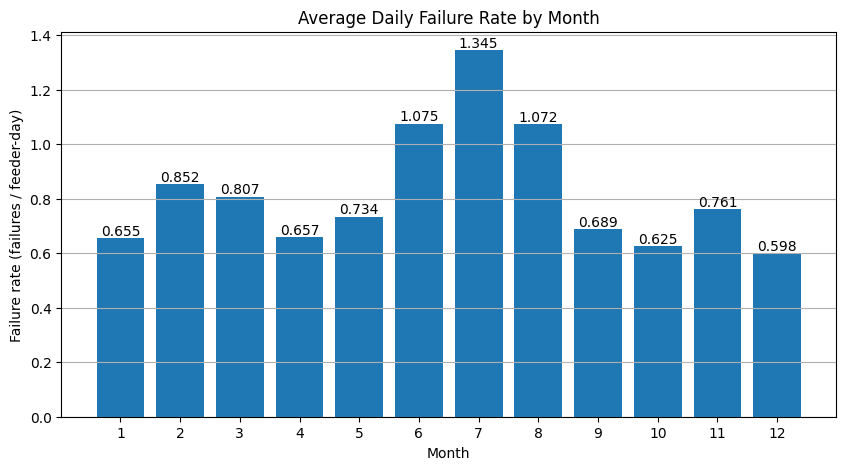

In [42]:
# ==========================================
# Seasonal Failure Analysis
# ==========================================

import matplotlib.pyplot as plt


# Total failures per month
monthly_failure_count = (
    daily_health
    .groupby("month")["unplanned_failures"]
    .sum()
)


# Number of feeder-days per month
monthly_days = (
    daily_health
    .groupby("month")
    .size()
)


# Failure rate per feeder-day
monthly_failure_rate = (
    monthly_failure_count /
    monthly_days
)


plt.figure(figsize=(10,5))

bars = plt.bar(
    monthly_failure_rate.index,
    monthly_failure_rate.values
)


plt.title(
    "Average Daily Failure Rate by Month"
)

plt.xlabel(
    "Month"
)

plt.ylabel(
    "Failure rate (failures / feeder-day)"
)


# Show values
for bar, value in zip(
    bars,
    monthly_failure_rate.values
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )


plt.xticks(
    range(1,13)
)

plt.grid(
    axis="y"
)

plt.show()

**Seasonal Failure Behavior**

The monthly failure rate shows clear seasonal variation.

The highest failure rate occurs during **July (month 7)**, followed by **June and August**, indicating increased failure activity during the summer period. Lower failure rates are observed in months such as **December, January, and October**.

This seasonal pattern suggests that environmental and operational conditions may influence feeder reliability. Possible factors include temperature-related stress, increased electrical demand, and seasonal network loading.

However, the pattern is not a simple yearly trend; failures occur in all months. Therefore, month-related features may provide useful predictive information, but they should be combined with feeder condition and operational features for reliable failure prediction.

Key modeling insight:

Month appears to be a potentially useful feature because failure risk changes across seasons. The model should learn these seasonal effects rather than assuming all days have the same baseline failure probability.

###**6) Weekday effect**

Question:

Are some weekdays more risky?

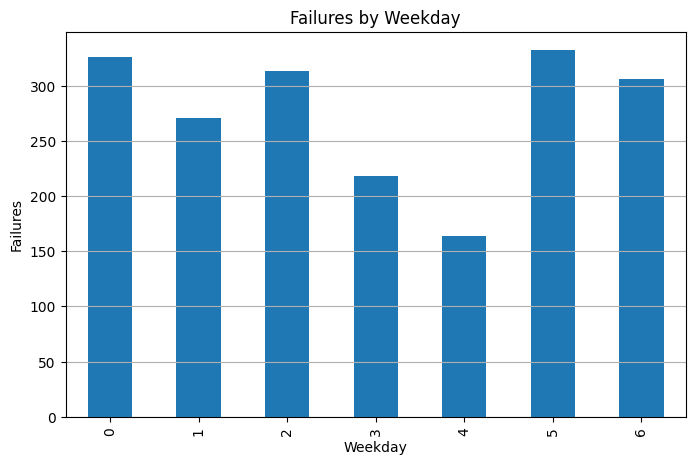

In [45]:
weekday_failure = (
    daily_health
    .groupby("weekday")
    ["unplanned_failures"]
    .sum()
)


plt.figure(figsize=(8,5))

weekday_failure.plot(
    kind="bar"
)

plt.title("Failures by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Failures")
plt.grid(axis="y")
plt.show()

In [46]:
# ==========================================
# Iranian weekday mapping
# ==========================================

iran_weekday_names = {
    0: "Saturday",
    1: "Sunday",
    2: "Monday",
    3: "Tuesday",
    4: "Wednesday",
    5: "Thursday",
    6: "Friday"
}


# Convert pandas weekday to Iranian weekday
daily_health["iran_weekday"] = (
    (daily_health["date"].dt.weekday + 2) % 7
)


daily_health["iran_weekday_name"] = (
    daily_health["iran_weekday"]
    .map(iran_weekday_names)
)


display(
    daily_health[
        [
            "date",
            "weekday",
            "iran_weekday",
            "iran_weekday_name"
        ]
    ].head(10)
)

,date,weekday,iran_weekday,iran_weekday_name
0,2016-03-24,3,5,Thursday
1,2016-03-29,1,3,Tuesday
2,2016-04-05,1,3,Tuesday
3,2016-04-06,2,4,Wednesday
4,2016-04-15,4,6,Friday
5,2016-04-23,5,0,Saturday
6,2016-04-24,6,1,Sunday
7,2016-04-25,0,2,Monday
8,2016-05-02,0,2,Monday
9,2016-05-09,0,2,Monday


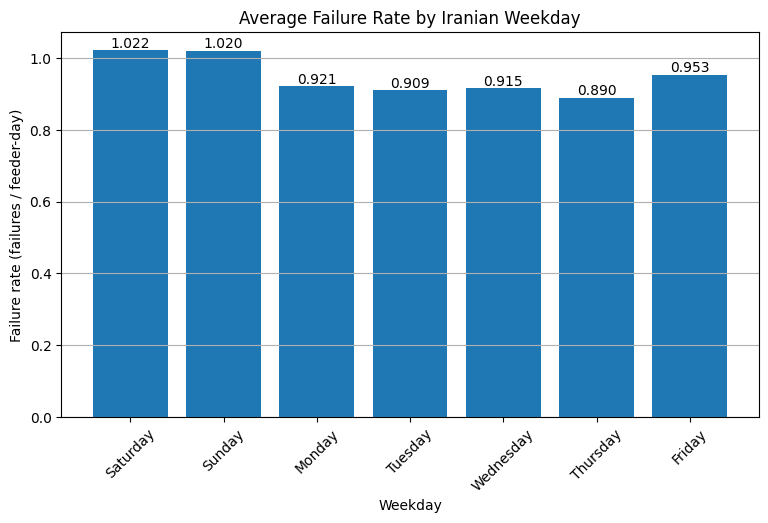

In [47]:
# ==========================================
# Failure rate by Iranian weekday
# ==========================================

weekday_failure_count = (
    daily_health
    .groupby("iran_weekday_name")
    ["unplanned_failures"]
    .sum()
)


weekday_total_days = (
    daily_health
    .groupby("iran_weekday_name")
    .size()
)


weekday_failure_rate = (
    weekday_failure_count /
    weekday_total_days
)


# Correct Iranian order
iran_order = [
    "Saturday",
    "Sunday",
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday"
]


weekday_failure_rate = (
    weekday_failure_rate
    .reindex(iran_order)
)


# Plot

plt.figure(figsize=(9,5))

bars = plt.bar(
    weekday_failure_rate.index,
    weekday_failure_rate.values
)


plt.title(
    "Average Failure Rate by Iranian Weekday"
)

plt.xlabel(
    "Weekday"
)

plt.ylabel(
    "Failure rate (failures / feeder-day)"
)

plt.xticks(
    rotation=45
)

plt.grid(
    axis="y"
)


for bar, value in zip(
    bars,
    weekday_failure_rate.values
):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )


plt.show()

**Weekday Failure Behavior**

The weekday analysis shows some variation in failure occurrence across the Iranian week.

When considering failure rate per feeder-day, the highest risk appears on **Saturday and Sunday**, while **Thursday shows the lowest failure rate**. The remaining weekdays have relatively similar failure levels.

The difference between weekdays is moderate, suggesting that weekly patterns may have some influence on feeder failures, but they are unlikely to be the main failure driver.

For predictive modeling, weekday information can be included as a temporal feature, but it should be combined with feeder condition, operational stress, and historical failure indicators.

Important observation:

The second plot (failure rate) is the correct interpretation for modeling. The first plot (total failures by weekday) is affected by how many feeder-days exist for each weekday, while the normalized failure rate gives a fair comparison.

###**7) Failure vs energy loss**

Question:
Are frequent failures also severe?

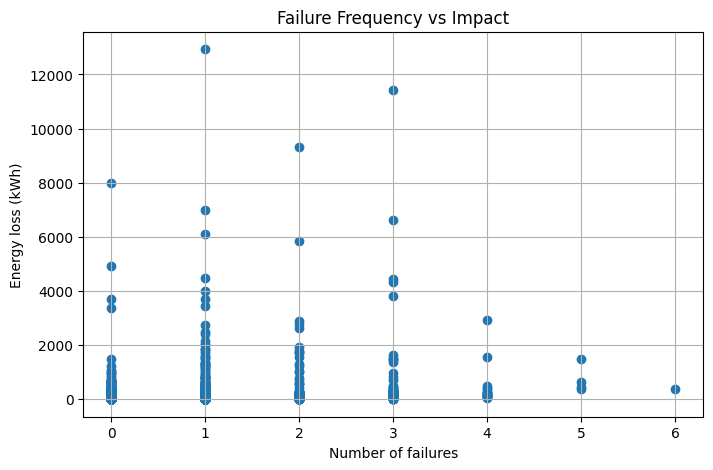

In [40]:
plt.figure(figsize=(8,5))

plt.scatter(
    daily_health["unplanned_failures"],
    daily_health["total_energy_loss"]
)

plt.xlabel("Number of failures")
plt.ylabel("Energy loss (kWh)")
plt.title("Failure Frequency vs Impact")

plt.grid(True)
plt.show()

**Failure Frequency vs Impact**

The relationship between failure frequency and energy loss is not strongly linear.

Most feeder-days contain a small number of failures with relatively low energy impact. However, some high-impact events occur even when the number of failures is low, indicating that failure severity depends not only on frequency but also on event characteristics.

Several extreme energy-loss cases are visible across different failure counts, suggesting that rare events can have a significant operational impact.

Therefore, the prediction model should consider both:
- failure occurrence frequency (how often failures happen)
- failure impact indicators (such as energy loss and outage duration)

A feeder with fewer failures is not necessarily safer if those failures cause larger consequences.

Modeling implication:

Failure count and failure severity represent different aspects of feeder reliability. Both should be included as separate features rather than assuming frequent failures always produce higher damage.

###**8) Correlation heatmap of numerical health features**

This helps understand redundancy.

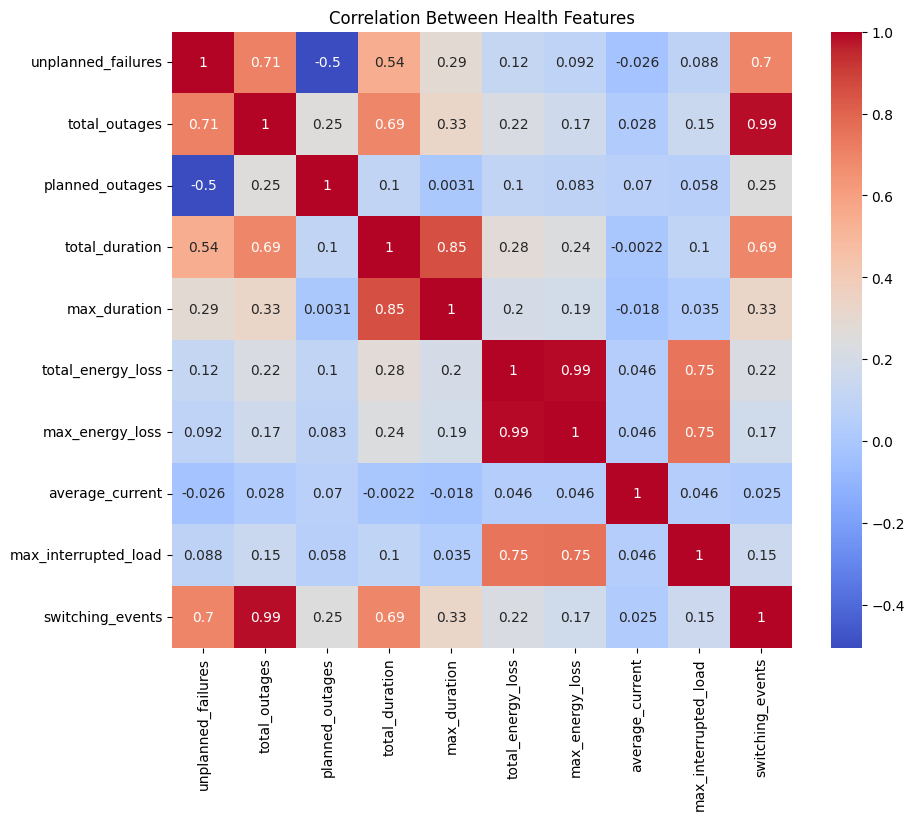

In [41]:
import seaborn as sns

numeric_cols = [
    "unplanned_failures",
    "total_outages",
    "planned_outages",
    "total_duration",
    "max_duration",
    "total_energy_loss",
    "max_energy_loss",
    "average_current",
    "max_interrupted_load",
    "switching_events"
]


plt.figure(figsize=(10,8))

sns.heatmap(
    daily_health[numeric_cols].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Health Features")
plt.show()

**Correlation Between Health Features**

The correlation analysis shows several groups of strongly related features.

Some features contain similar information:
- `total_outages` and `switching_events` are highly correlated (~0.99), because both represent the number of daily operational events.
- `total_energy_loss` and `max_energy_loss` are highly correlated (~0.99), meaning that the largest energy-loss event often dominates the daily total.
- `total_duration` and `max_duration` have a strong relationship (~0.85), indicating that long daily interruptions are usually caused by a severe single event.

Failure occurrence (`unplanned_failures`) has a strong positive relationship with:
- `total_outages` (~0.71)
- `switching_events` (~0.70)
- `total_duration` (~0.54)

This indicates that higher operational activity is generally associated with more unplanned failures.

Some features, such as `average_current`, show very weak correlation with other health indicators. This does not necessarily mean they are useless, because non-linear models may still extract predictive patterns from them.

For modeling, highly correlated features should be monitored to avoid redundancy. However, tree-based models can usually handle correlated variables, so feature removal should be based on model performance rather than correlation alone.

Key modeling insight:

The dataset contains several groups of related reliability indicators. Before model training, feature importance analysis will be useful to determine whether all correlated features contribute meaningful predictive information.

In [49]:
daily_health

,mv_feeder_gis,date,unplanned_failures,total_outages,planned_outages,total_duration,max_duration,total_energy_loss,max_energy_loss,average_current,...,lv_feeder_21.0,lv_feeder_9999.0,lv_feeder_101782.0,year,month,day,weekday,weekday_name,iran_weekday,iran_weekday_name
0,112240,2016-03-24,1,1,0,36,36,16.750440,16.750440,79.000,...,False,False,False,2016,3,24,3,Thursday,5,Thursday
1,112240,2016-03-29,1,1,0,70,70,84.277742,84.277742,2.000,...,0,0,0,2016,3,29,1,Tuesday,3,Tuesday
2,112240,2016-04-05,1,1,0,47,47,5.867878,5.867878,70.000,...,False,False,False,2016,4,5,1,Tuesday,3,Tuesday
3,112240,2016-04-06,0,1,1,20,20,8.471666,8.471666,87.000,...,False,False,False,2016,4,6,2,Wednesday,4,Wednesday
4,112240,2016-04-15,1,1,0,139,139,51.703025,51.703025,79.000,...,False,False,False,2016,4,15,4,Friday,6,Friday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2031,112320,2025-08-18,1,1,0,16,16,25.020000,25.020000,160.000,...,False,False,False,2025,8,18,0,Monday,2,Monday
2032,112320,2025-08-25,1,3,2,221,120,6099.980003,6000.000000,120.110,...,False,False,False,2025,8,25,0,Monday,2,Monday
2033,112320,2025-08-29,1,1,0,110,110,135.319993,135.319993,158.330,...,False,False,False,2025,8,29,4,Friday,6,Friday
2034,112320,2025-09-06,1,1,0,90,90,55.390000,55.390000,94.670,...,False,False,False,2025,9,6,5,Saturday,0,Saturday


In [50]:
# ==========================================
# Create daily failure indicator
# ==========================================

# Binary failure indicator:
# 1 = at least one unplanned failure happened that day
# 0 = no unplanned failure happened

daily_health["failure_binary"] = (
    daily_health["unplanned_failures"] > 0
).astype(int)


# ==========================================
# Reorder important columns first
# ==========================================

cols = daily_health.columns.tolist()

priority_cols = [
    "date",
    "unplanned_failures",
    "failure_binary"
]

remaining_cols = [
    c for c in cols
    if c not in priority_cols
]


daily_health = daily_health[
    priority_cols + remaining_cols
]


# Check result

display(
    daily_health.head()
)

print(
    daily_health.columns[:10].tolist()
)

,date,unplanned_failures,failure_binary,mv_feeder_gis,total_outages,planned_outages,total_duration,max_duration,total_energy_loss,max_energy_loss,...,lv_feeder_21.0,lv_feeder_9999.0,lv_feeder_101782.0,year,month,day,weekday,weekday_name,iran_weekday,iran_weekday_name
0,2016-03-24,1,1,112240,1,0,36,36,16.750440,16.750440,...,False,False,False,2016,3,24,3,Thursday,5,Thursday
1,2016-03-29,1,1,112240,1,0,70,70,84.277742,84.277742,...,0,0,0,2016,3,29,1,Tuesday,3,Tuesday
2,2016-04-05,1,1,112240,1,0,47,47,5.867878,5.867878,...,False,False,False,2016,4,5,1,Tuesday,3,Tuesday
3,2016-04-06,0,0,112240,1,1,20,20,8.471666,8.471666,...,False,False,False,2016,4,6,2,Wednesday,4,Wednesday
4,2016-04-15,1,1,112240,1,0,139,139,51.703025,51.703025,...,False,False,False,2016,4,15,4,Friday,6,Friday


['date', 'unplanned_failures', 'failure_binary', 'mv_feeder_gis', 'total_outages', 'planned_outages', 'total_duration', 'max_duration', 'total_energy_loss', 'max_energy_loss']


In [51]:
# ==========================================
# Save Final Daily Feeder Health Dataset
# ==========================================

output_path = "/content/daily_feeder_health.csv"

daily_health.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print("Saved successfully:")
print(output_path)

print("Final shape:")
print(daily_health.shape)

Saved successfully:
/content/daily_feeder_health.csv
Final shape:
(2036, 434)
